# Final poster-figure notebook

This notebook exports high-resolution poster figures. Use the **400-dpi PNG exports** in PowerPoint via **Insert → Picture** or **Change Picture**; dragging PDFs into PowerPoint can rasterize them unpredictably.

Poster-level titles, captions, and statistical notes should be added in PowerPoint. The figures keep only axes, ticks, model labels/legends, and uncertainty marks.


# Clean poster figures — line-cutting universalization

This notebook produces the figures used in the poster results section:

1. **Fit to explicit universalizability judgments** — participant-bootstrap Pearson $r$.
2. **Model–human scatterplots** — three panels: L0, L1 shallow, L1 rollout.
3. **Fit versus compute** — Pearson $r$ versus runtime, with runtime IQRs.
4. **Moral-judgment contribution** — pooled and country-level $\Delta R^2$ beyond outcome controls.
5. **Paired bootstrap contrasts** — model differences for the statistics printed on the poster.


In [1]:
# ============================================================
# 0. VISUAL CONFIGURATION — edit this cell to restyle everything
# ============================================================
from pathlib import Path
import matplotlib as mpl
from matplotlib import font_manager

FIG_DIR = Path("figures/poster_clean")
FIG_DIR.mkdir(parents=True, exist_ok=True)

STYLE = {
    # Typography
    "font_family": "Avenir Next",
    "font_fallback": "DejaVu Sans",
    "base_fontsize": 17,
    "title_fontsize": 21,
    "label_fontsize": 18,
    "tick_fontsize": 13,
    "annotation_fontsize": 14,

    # Geometry
    "dpi": 400,
    "line_width": 1.8,
    "marker_size": 68,
    "bar_height": 0.56,

    # Neutral styling
    "text": "#202124",
    "secondary_text": "#5F6368",
    "grid": "#D8D4CC",
    "point_fill": "#F7F5F0",
    "point_edge": "#4B4F52",
    "regression": "#4B4F52",

    # Depth palette: hue = planning depth; lighter shade = higher ToM level
    "D0": "#D95F4C",       # L0
    "D1": "#2F6DB2",       # L1 heuristic
    "D1_light": "#8EADD2", # L2 heuristic
    "D2": "#7A5AA6",       # real L1
    "D2_light": "#B6A4C9", # real L2
}

MODEL_COLORS = {
    "L0": STYLE["D0"],
    "L1 heuristic": STYLE["D1"],
    "L2 heuristic": STYLE["D1_light"],
    "real L1": STYLE["D2"],
    "real L2": STYLE["D2_light"],
}

MODEL_LABELS = {
    "L0": "L0",
    "L1 heuristic": "L1 shallow",
    "L2 heuristic": "L2 shallow",
    "real L1": "L1 rollout",
    "real L2": "L2 rollout",
}

MODEL_ORDER = ["L0", "L1 heuristic", "L2 heuristic", "real L1", "real L2"]

# Poster-facing titles. Set any title to None for no title.
TITLES = {
    "fit_univ": None,
    "scatter": None,
    "fit_compute": None,
    "moral_dr2": None,
    "country_dr2": None,
    "country_r": None,
}

# Axis limits; change to None for automatic limits.
LIMITS = {
    "fit_r": (0.50, 1.02),
    "fit_compute_r": (0.55, 0.90),
    "moral_dr2": (0.00, None),
    "country_dr2": (0.00, None),
}


# Figure slots in the current PowerPoint poster, in inches.
# Use these values directly as figsize so the exported PNG matches the PowerPoint box.
POSTER_FIGSIZE = {
    "fit_univ": (15.00, 6.67),
    "scatters": (15.00, 4.51),
    "fit_compute": (6.85, 5.13),
    "us_dr2": (15.00, 6.27),
    "country_dr2": (8.51, 10.75),
}

# Bootstrap settings
N_BOOT_POSTER = 2000
N_BOOT_COUNTRY = 2000
BOOT_SEED = 42

# Expensive country-level analyses. Raw-r plot is the main cross-cultural figure.
RUN_COUNTRY_R_BOOTSTRAPS = False
RUN_COUNTRY_DR2_BOOTSTRAPS = True  # optional robustness figure

# Use Avenir Next when installed; otherwise fall back cleanly.
installed = {f.name for f in font_manager.fontManager.ttflist}
ACTIVE_FONT = STYLE["font_family"] if STYLE["font_family"] in installed else STYLE["font_fallback"]
print(f"Matplotlib font: {ACTIVE_FONT}")

mpl.rcParams.update({
    "font.family": ACTIVE_FONT,
    "font.size": STYLE["base_fontsize"],
    "axes.titlesize": STYLE["title_fontsize"],
    "axes.labelsize": STYLE["label_fontsize"],
    "xtick.labelsize": STYLE["tick_fontsize"],
    "ytick.labelsize": STYLE["tick_fontsize"],
    "text.color": STYLE["text"],
    "axes.labelcolor": STYLE["text"],
    "axes.edgecolor": STYLE["text"],
    "xtick.color": STYLE["text"],
    "ytick.color": STYLE["text"],
    "savefig.dpi": STYLE["dpi"],
    "figure.dpi": 150,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


Matplotlib font: Avenir Next


## 1. Imports and run configuration

The run labels below match the frozen poster configuration. Change only the values if a newer run replaces one of them.


In [2]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from new_comparison_utils import (
    load_experiments,
    load_simulations,
    load_outcome_metrics,
    build_all_design_matrices,
    evaluate_fits,
)
from bootstrap_significance import (
    bootstrap_over_participants,
    bootstrap_delta_r2,
    bootstrap_pairwise,
)

# These two modules are used by the current cross-cultural pipeline.
from logan_individual import load_logan_individual
try:
    import fast_bootstrap
    fast_bootstrap.install()
except ImportError:
    print("fast_bootstrap not found: results remain correct, but Logan bootstraps will be slow.")

RUNS = {
    "L0":           "L0_ghost_flat",
    "L1 heuristic": "L1h_ghost_flat",
    "L2 heuristic": "L2h_ghost_flat",
    "real L1":      "realL1_fixed_flat",
    "real L2":      "realL2_fixed_flat",
}


fast_bootstrap installed: _resample_means vectorized (cached participant x stimulus matrix).


## 2. Load data

Set `recompute=False` for ordinary figure work. Use `True` only after simulation files change.


In [4]:
RECOMPUTE_SIM_SUMMARIES = True

datasets = load_experiments(
    joe_moral_agg="joe_moral_agg.csv",
    joe_moral_long="joe_moral_long.csv",
    joe_univ_agg="joe_univ_agg.csv",
    joe_univ_long="joe_univ_long.csv",
)

logan_pooled, logan_by_country = load_logan_individual()
datasets["logan_moral"] = logan_pooled

sims = load_simulations(RUNS, recompute=RECOMPUTE_SIM_SUMMARIES)
out_df = load_outcome_metrics()

dm = {
    key: build_all_design_matrices(sims, out_df, experiment)
    for key, experiment in datasets.items()
}

ev_univ = evaluate_fits(dm["joe_univ"], datasets["joe_univ"])
ev_moral = evaluate_fits(dm["joe_moral"], datasets["joe_moral"])
ev_logan = evaluate_fits(dm["logan_moral"], datasets["logan_moral"])

ev_univ[["tag", "n", "r_U_AW", "delta_R2"]].round(3)


Processed 28 maps for run_label='L0_ghost_flat' and saved to ../data/simulations/L0_ghost_flat/processed
Built universalization summary for run_label='L0_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  Excluded 6/280 stuck runs (2.1%)
  L0                    28 maps, 10 runs  mean U_AW=-3.049  stuck=6/280 (2.1%)
Processed 28 maps for run_label='L1h_ghost_flat' and saved to ../data/simulations/L1h_ghost_flat/processed
Built universalization summary for run_label='L1h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L1 heuristic          28 maps, 10 runs  mean U_AW=-1.166  stuck=0/280 (0.0%)
Processed 28 maps for run_label='L2h_ghost_flat' and saved to ../data/simulations/L2h_ghost_flat/processed
Built universalization summary for run_label='L2h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L2 heuristic          28 maps, 10 runs  mean U_AW=-1.217  stuck=0/280 (0.0%)
Processed 28 maps for run_label='re

,tag,n,r_U_AW,delta_R2
0,L1 heuristic,39,0.845,0.390
1,L2 heuristic,39,0.842,0.387
2,real L1,39,0.843,0.381
3,real L2,39,0.834,0.359
4,L0,39,0.670,0.149


## 3. Clean plotting helpers

These functions are self-contained. Poster edits should usually require changing only `STYLE`, `TITLES`, and `LIMITS`, not this cell.


In [5]:

def clean_axes(ax, grid_axis=None):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    if grid_axis:
        ax.grid(axis=grid_axis, color=STYLE["grid"], linewidth=0.8, alpha=0.65)
        ax.set_axisbelow(True)


def export_figure(fig, stem, tight=False):
    """
    Save editable vector files plus a print-resolution PNG.

    By default, bbox_inches is None so the exported PNG keeps the exact figsize
    requested in the plotting call. Use tight=True only for diagnostic exports.
    """
    stem = FIG_DIR / stem
    bbox = "tight" if tight else None
    fig.savefig(stem.with_suffix(".pdf"), bbox_inches=bbox)
    fig.savefig(stem.with_suffix(".svg"), bbox_inches=bbox)
    fig.savefig(stem.with_suffix(".png"), dpi=STYLE["dpi"], bbox_inches=bbox)
    print(f"Saved: {stem}.pdf / .svg / .png at {fig.get_size_inches()[0]:.2f} × {fig.get_size_inches()[1]:.2f} in, {STYLE['dpi']} dpi")


def summarize_bootstrap(boot_values):
    rows = []
    for tag, values in boot_values.items():
        x = np.asarray(values, dtype=float)
        x = x[np.isfinite(x)]
        rows.append({
            "tag": tag,
            "mean": np.mean(x),
            "median": np.median(x),
            "lo": np.percentile(x, 2.5),
            "hi": np.percentile(x, 97.5),
        })
    return pd.DataFrame(rows)


def plot_bootstrap_intervals(
    boot_values,
    order=MODEL_ORDER,
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    xlabel="Pearson $r$",
    title=None,
    xlim=None,
    value_decimals=2,
    figsize=(8.2, 4.8),
    stem=None,
):
    """Dot-and-whisker plot. Cleaner than bars when CIs overlap."""
    summary = summarize_bootstrap(boot_values).set_index("tag")
    shown = [tag for tag in order if tag in summary.index]
    shown = list(reversed(shown))
    y = np.arange(len(shown))

    fig, ax = plt.subplots(figsize=figsize)
    for yi, tag in zip(y, shown):
        row = summary.loc[tag]
        color = colors[tag]
        ax.plot([row.lo, row.hi], [yi, yi], color=color,
                linewidth=STYLE["line_width"], solid_capstyle="round")
        ax.scatter(row["mean"], yi, s=STYLE["marker_size"],
                   color=color, edgecolor="white", linewidth=0.8, zorder=3)
        offset = 0.012 * ((xlim[1] - xlim[0]) if xlim and None not in xlim else 1)
        ax.text(row.hi + offset, yi, f'{row["mean"]:.{value_decimals}f}',
                va="center", fontsize=STYLE["annotation_fontsize"],
                color=STYLE["secondary_text"])

    ax.set_yticks(y)
    ax.set_yticklabels([labels.get(tag, tag) for tag in shown])
    ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title, loc="left", pad=10, fontweight="semibold")
    if xlim:
        ax.set_xlim(*xlim)
    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.2)
    fig.subplots_adjust(left=0.09, right=0.99, bottom=0.18, top=0.84, wspace=0.20)
    if stem:
        export_figure(fig, stem)
    return fig, ax, summary.reset_index()


def _regression_band(x, y, grid, confidence=0.95):
    """Analytic confidence band for the mean OLS regression line."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    slope, intercept, _, _, _ = stats.linregress(x, y)
    fitted = intercept + slope * grid
    resid = y - (intercept + slope * x)
    n = len(x)
    if n <= 2:
        return fitted, fitted, fitted
    s_err = np.sqrt(np.sum(resid**2) / (n - 2))
    xbar = np.mean(x)
    ssx = np.sum((x - xbar)**2)
    se_mean = s_err * np.sqrt(1/n + (grid - xbar)**2 / ssx)
    crit = stats.t.ppf((1 + confidence) / 2, n - 2)
    return fitted, fitted - crit * se_mean, fitted + crit * se_mean


def plot_model_human_scatters(
    design_mats,
    experiment,
    tags=("L0", "L1 heuristic", "real L1"),
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    metric="univ_aggregate_welfare",
    xlabel="Model score",
    ylabel="Human judgment",
    title=None,
    xlim=None,
    ylim=None,
    label_outliers=0,
    figsize_per_panel=(4.2, 4.0),
    figsize=None,
    stem=None,
):
    """Neutral points; model identity is carried by line/title color only."""
    dv = experiment.dv_col
    n = len(tags)
    if figsize is None:
        figsize = (figsize_per_panel[0] * n, figsize_per_panel[1])
    fig, axes = plt.subplots(
        1, n, figsize=figsize,
        sharey=True, squeeze=False
    )
    axes = axes.ravel()

    for idx, (ax, tag) in enumerate(zip(axes, tags)):
        df = design_mats[tag].dropna(subset=[metric, dv]).copy()
        x = df[metric].to_numpy(float)
        y = df[dv].to_numpy(float)
        r = stats.pearsonr(x, y).statistic
        color = colors[tag]

        ax.scatter(
            x, y,
            s=STYLE["marker_size"] * 0.72,
            facecolor=STYLE["point_fill"],
            edgecolor=STYLE["point_edge"],
            linewidth=1.0,
            alpha=0.95,
            zorder=2,
        )

        grid = np.linspace(np.min(x), np.max(x), 200)
        fit, lo, hi = _regression_band(x, y, grid)
        ax.fill_between(grid, lo, hi, color=color, alpha=0.13, linewidth=0)
        ax.plot(grid, fit, color=color, linewidth=STYLE["line_width"])

        if label_outliers:
            slope, intercept, *_ = stats.linregress(x, y)
            df["_abs_resid"] = np.abs(y - (intercept + slope * x))
            for _, row in df.nlargest(label_outliers, "_abs_resid").iterrows():
                ax.annotate(
                    row.get("stimulus", ""),
                    (row[metric], row[dv]),
                    xytext=(5, 5), textcoords="offset points",
                    fontsize=STYLE["annotation_fontsize"] - 3,
                    color=STYLE["secondary_text"],
                )

        ax.set_title(
            f'{labels.get(tag, tag)}  ·  $r$ = {r:.2f}',
            color=color, loc="left", fontweight="semibold", pad=9
        )
        ax.set_xlabel(xlabel)
        if idx == 0:
            ax.set_ylabel(ylabel)
        if xlim:
            ax.set_xlim(*xlim)
        if ylim:
            ax.set_ylim(*ylim)
        clean_axes(ax)

    if title:
        fig.suptitle(title, x=0.02, ha="left", fontweight="semibold")
    fig.tight_layout(pad=1.1)
    fig.subplots_adjust(left=0.07, right=0.99, bottom=0.18, top=0.82, wspace=0.22)
    if stem:
        export_figure(fig, stem)
    return fig, axes


def load_compute_samples(run_labels, sim_root="../data/simulations"):
    """One timing sample per simulation run row, preserving map/run variation."""
    samples = {}
    for tag, label in run_labels.items():
        files = glob.glob(f"{sim_root}/{label}/raw/*.csv")
        if not files:
            print(f"No timing files for {tag}: {label}")
            continue
        frames = []
        for f in files:
            df = pd.read_csv(f)
            if "run_elapsed_seconds" in df.columns:
                frames.append(df[["run_elapsed_seconds"]])
        if frames:
            x = pd.concat(frames, ignore_index=True)["run_elapsed_seconds"]
            samples[tag] = x[np.isfinite(x)].to_numpy()
    return samples


def plot_fit_vs_compute(
    compute_samples,
    boot_r,
    order=MODEL_ORDER,
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    title=None,
    ylim=None,
    show_compute_iqr=True,
    figsize=(7.0, 5.2),
    stem=None,
):
    """
    Median compute on a log x-axis, mean bootstrap r on y.
    Horizontal whiskers show compute IQR; vertical whiskers show 95% bootstrap CI.
    """
    fit = summarize_bootstrap(boot_r).set_index("tag")
    fig, ax = plt.subplots(figsize=figsize)

    for tag in order:
        if tag not in compute_samples or tag not in fit.index:
            continue
        times = np.asarray(compute_samples[tag], dtype=float)
        times = times[np.isfinite(times) & (times > 0)]
        median_t = np.median(times)
        q1, q3 = np.percentile(times, [25, 75])
        row = fit.loc[tag]

        xerr = [[median_t - q1], [q3 - median_t]] if show_compute_iqr else None
        yerr = [[row["mean"] - row.lo], [row.hi - row["mean"]]]

        ax.errorbar(
            median_t, row["mean"],
            xerr=xerr, yerr=yerr,
            fmt="o", markersize=8.5,
            color=colors[tag],
            ecolor=colors[tag],
            elinewidth=1.4, capsize=3,
            markeredgecolor="white", markeredgewidth=0.8,
            zorder=3,
            label=labels.get(tag, tag),
        )
        # Model names are handled in a legend rather than direct labels,
        # preventing overlap when fit values are tightly clustered.

    ax.set_xscale("log")
    ax.set_xlabel("Compute time (seconds, log scale)")
    ax.set_ylabel("Pearson $r$")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    # Fewer y-axis labels: exact intermediate values are not substantively important.
    from matplotlib.ticker import MultipleLocator
    ax.yaxis.set_major_locator(MultipleLocator(0.10))
    clean_axes(ax, grid_axis="both")
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        borderaxespad=0,
        fontsize=STYLE["tick_fontsize"],
        handletextpad=0.5,
        labelspacing=0.45,
    )
    # Leave room for the external legend and axis text.
    fig.subplots_adjust(left=0.16, right=0.72, bottom=0.18, top=0.92)
    if stem:
        export_figure(fig, stem)
    return fig, ax


def plot_moral_dr2(
    boot_by_dataset,
    dataset_labels,
    model_tags=("L1 heuristic", "real L1"),
    model_labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    title=None,
    xlim=None,
    figsize=(8.2, 4.5),
    stem=None,
):
    """
    Grouped dot-and-whisker plot of participant-bootstrap ΔR².
    One row per moral-judgment dataset; one point per model.
    """
    datasets_shown = list(boot_by_dataset.keys())
    fig, ax = plt.subplots(figsize=figsize)
    offsets = np.linspace(-0.14, 0.14, len(model_tags))

    for j, tag in enumerate(model_tags):
        means, los, his = [], [], []
        for key in datasets_shown:
            values = np.asarray(boot_by_dataset[key][tag], dtype=float)
            values = values[np.isfinite(values)]
            means.append(np.mean(values))
            los.append(np.percentile(values, 2.5))
            his.append(np.percentile(values, 97.5))
        y = np.arange(len(datasets_shown)) + offsets[j]
        means = np.asarray(means)
        ax.errorbar(
            means, y,
            xerr=[means - np.asarray(los), np.asarray(his) - means],
            fmt="o", markersize=8,
            color=colors[tag], ecolor=colors[tag],
            elinewidth=1.5, capsize=3,
            markeredgecolor="white", markeredgewidth=0.8,
            label=model_labels.get(tag, tag),
        )

    ax.set_yticks(np.arange(len(datasets_shown)))
    ax.set_yticklabels([dataset_labels[k] for k in datasets_shown])
    ax.set_xlabel("$\\Delta R^2$ beyond welfare, harm, and inequality")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if xlim:
        left, right = xlim
        ax.set_xlim(left=left, right=right)
    ax.legend(frameon=False, loc="best")
    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.1)
    fig.subplots_adjust(left=0.07, right=0.99, bottom=0.18, top=0.82, wspace=0.22)
    if stem:
        export_figure(fig, stem)
    return fig, ax


def plot_country_dr2(
    country_df,
    tag="L1 heuristic",
    pooled_boot=None,
    pooled_label="Pooled (20 countries)",
    pooled_first=True,
    color=None,
    title=None,
    xlim=None,
    figsize=(7.0, 8.4),
    stem=None,
):
    """
    Country forest plot using participant-bootstrap ΔR².
    Optionally adds the pooled 20-country estimate as a visually separated row.
    """
    color = color or MODEL_COLORS[tag]
    sub = country_df[country_df["tag"] == tag].copy()

    if pooled_boot is not None:
        values = np.asarray(pooled_boot[tag], dtype=float)
        values = values[np.isfinite(values)]
        pooled_row = pd.DataFrame([{
            "country": pooled_label,
            "tag": tag,
            "mean": np.mean(values),
            "lo": np.percentile(values, 2.5),
            "hi": np.percentile(values, 97.5),
            "_pooled": True,
        }])
        sub["_pooled"] = False
        sub = pd.concat([pooled_row, sub], ignore_index=True)
    else:
        sub["_pooled"] = False

    countries = sub[~sub["_pooled"]].sort_values("mean", ascending=False)
    pooled = sub[sub["_pooled"]]

    if len(pooled):
        sub = pd.concat([pooled, countries], ignore_index=True) if pooled_first else pd.concat([countries, pooled], ignore_index=True)
    else:
        sub = countries.reset_index(drop=True)

    # Reverse y positions so the first row appears at the top.
    y = np.arange(len(sub))[::-1]

    fig, ax = plt.subplots(figsize=figsize)
    ax.errorbar(
        sub["mean"], y,
        xerr=[sub["mean"] - sub["lo"], sub["hi"] - sub["mean"]],
        fmt="o", markersize=6.5,
        color=color, ecolor=color,
        elinewidth=1.3, capsize=2,
        markeredgecolor="white", markeredgewidth=0.7,
    )

    ax.axvline(0, color=STYLE["secondary_text"], linewidth=1.0)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["country"])
    ax.set_xlabel("$\\Delta R^2$ beyond outcome-based measures")

    # Visually separate pooled estimate from country rows.
    if len(pooled):
        if pooled_first:
            sep_y = y[0] - 0.5
        else:
            sep_y = y[-1] + 0.5
        ax.axhline(sep_y, color=STYLE["secondary_text"], linewidth=1.0, linestyle=":")

        # Bold the pooled label.
        ticklabels = ax.get_yticklabels()
        pooled_index = 0 if pooled_first else len(ticklabels) - 1
        ticklabels[pooled_index].set_fontweight("semibold")

    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if xlim:
        left, right = xlim
        ax.set_xlim(left=left, right=right)

    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.1)
    if stem:
        export_figure(fig, stem)
    return fig, ax


### Poster assembly note

Use the `POSTER_FIGSIZE` values in the plotting calls below. They match the current PowerPoint figure boxes in inches. The PNG exports are 400 dpi and preserve the requested canvas size. Insert those PNGs into PowerPoint; do not drag PDFs into the slide.

Suggested caption for the fit plot: **Dots show mean Pearson correlations; whiskers show 95% participant-bootstrap confidence intervals; dotted line shows the split-half noise ceiling.**


## 4. Result figure 1 — fit to explicit universalizability judgments

This is the direct model-computation test, so the metric is Pearson $r$. The lighter shades indicate a higher model-of-others level within the same planning depth.

The chart uses dots rather than filled bars because the confidence intervals overlap strongly; the visual emphasis is on the shallow family rather than on tiny nominal differences within that family.


### Noise ceiling for the fit figure

Uses the existing pipeline helper `split_half_all(datasets)` (random split-half of participants → Spearman–Brown → √ = ceiling on model–mean $r$). Shown as a single dashed line: the split-half CI maps to a band ≈ .01 wide on this axis, invisible at poster scale.

**Wording consequence:** with the ceiling visible (≈ .99), do **not** say depth-1 models "reach the fit ceiling" — they **plateau at depth 1**, well below it. The remaining gap is headroom for better models (supports the next-steps framing).


In [6]:
# Noise ceiling from the existing pipeline helper.
try:
    split_half_all
except NameError:
    _imported = False
    for _mod in ("new_comparison_utils", "bootstrap_significance"):
        try:
            split_half_all = getattr(__import__(_mod), "split_half_all")
            _imported = True
            break
        except (ImportError, AttributeError):
            continue
    if not _imported:
        raise ImportError("split_half_all not found — import it from wherever it lives.")

ceilings = split_half_all(datasets)
display(ceilings)

_row = ceilings[ceilings["name"].str.contains("univ", case=False)].iloc[0]
NOISE_CEILING = {"value": float(_row["noise_ceiling"])}
print(f"Noise ceiling (Joe univ): r ≤ {NOISE_CEILING['value']:.4f}")


,name,n_participants,n_stimuli,r_half,ci_lo,ci_hi,spearman_brown,noise_ceiling
0,"Logan moral (pooled, ind)",1924,40,0.9929,0.9893,0.9958,0.9964,0.9982
1,Joe moral,39,39,0.9680,0.9431,0.9825,0.9837,0.9918
2,Joe univ,43,39,0.9615,0.9321,0.9800,0.9804,0.9901


Noise ceiling (Joe univ): r ≤ 0.9901


Saved: figures/poster_clean/01_fit_universalizability_r.pdf / .svg / .png at 15.00 × 6.67 in, 400 dpi
Saved: figures/poster_clean/01_fit_universalizability_r.pdf / .svg / .png at 15.00 × 6.67 in, 400 dpi


,tag,mean,median,lo,hi
0,L0,0.664,0.664,0.620,0.704
1,L1 heuristic,0.837,0.837,0.808,0.862
2,L2 heuristic,0.834,0.834,0.805,0.860
3,real L1,0.835,0.835,0.807,0.862
4,real L2,0.826,0.826,0.795,0.857


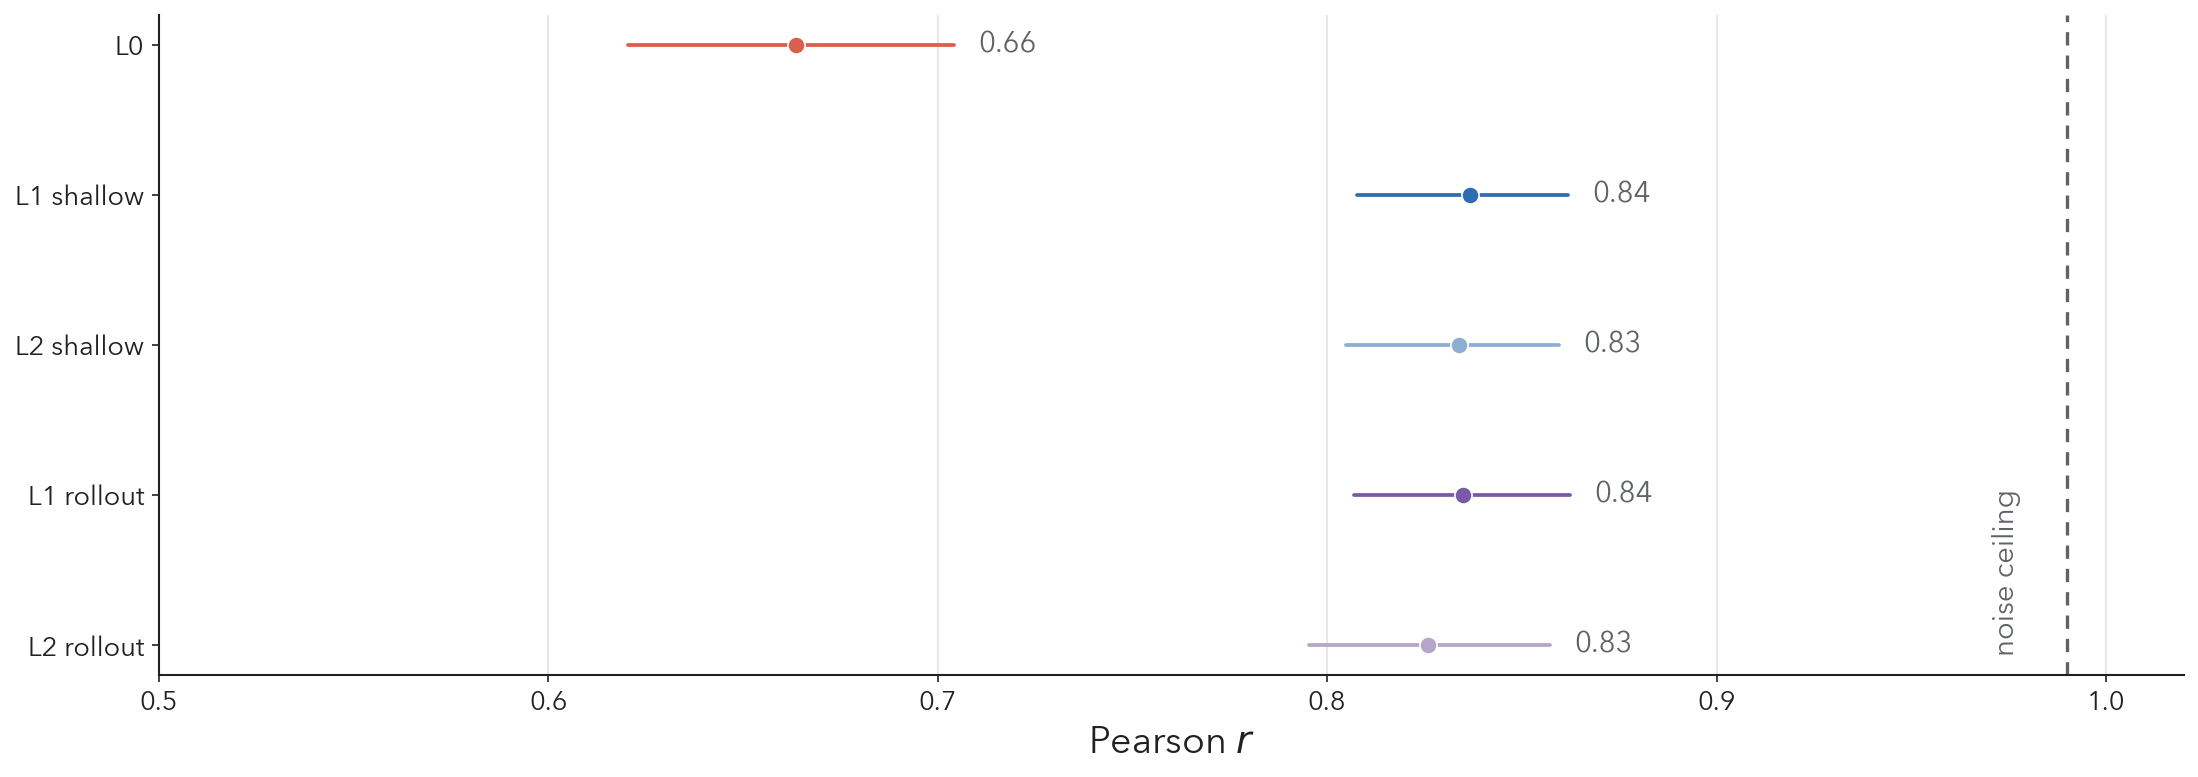

In [7]:
ci_r_univ, boot_r_univ = bootstrap_over_participants(
    dm["joe_univ"],
    datasets["joe_univ"],
    n_boot=N_BOOT_POSTER,
    seed=BOOT_SEED,
)

fig, ax, fit_r_summary = plot_bootstrap_intervals(
    boot_r_univ,
    order=MODEL_ORDER,
    xlabel="Pearson $r$",
    title=TITLES["fit_univ"],
    xlim=LIMITS["fit_r"],
    value_decimals=2,
    figsize=POSTER_FIGSIZE["fit_univ"],
    stem="01_fit_universalizability_r",
)

# Noise-ceiling reference line (single dashed line; split-half CI is ~.01 wide here).
ax.axvline(NOISE_CEILING["value"], color=STYLE["secondary_text"],
           lw=1.6, ls=(0, (4, 3)), zorder=1)
_ylo, _yhi = ax.get_ylim()
ax.text(NOISE_CEILING["value"] - 0.012, _ylo + 0.03 * (_yhi - _ylo),
        "noise ceiling", rotation=90, ha="right", va="bottom",
        fontsize=STYLE["annotation_fontsize"], color=STYLE["secondary_text"])

# Re-export with the ceiling annotation, preserving the exact requested figsize.
export_figure(fig, "01_fit_universalizability_r", tight=False)

fit_r_summary.round(3)


## Statistical contrasts for poster and session

These tests use **paired bootstrap draws**: within each bootstrap iteration, the same resampled participants contribute to every model. The reported contrasts therefore test differences between models directly rather than comparing overlapping confidence intervals.

Primary contrasts:

1. **Shallow prediction − no prediction**: L1 heuristic minus L0.
2. **Rollout − shallow prediction**: real L1 minus L1 heuristic.
3. For moral judgments, the same contrasts are applied to incremental $\Delta R^2$.

The notebook reports two-sided bootstrap $p$ values by default. One-sided tail probabilities are also included for descriptive use, but the two-sided values are the safer poster/session statistics unless a directional test was preregistered.

**Reporting note.** Bootstrap $p$ values use add-one smoothing, so they can never be exactly 0; with `N_BOOT_POSTER = 2000` the smallest reportable value is $2/2001 \approx .001$. On the poster, report these as **$p < .001$** (not $p = 0$ or $p < .0001$).


In [8]:
def paired_bootstrap_contrast(boot, model_a, model_b, ci=95):
    """Summarize paired bootstrap difference: model_a - model_b."""
    a = np.asarray(boot[model_a], dtype=float)
    b = np.asarray(boot[model_b], dtype=float)
    mask = np.isfinite(a) & np.isfinite(b)
    diff = a[mask] - b[mask]
    if diff.size == 0:
        raise ValueError(f"No finite paired draws for {model_a} and {model_b}")

    alpha = (100 - ci) / 2
    lo, hi = np.percentile(diff, [alpha, 100 - alpha])

    # Bootstrap tail probabilities relative to zero.
    # Add-one smoothing (Davison & Hinkley): with n draws the smallest
    # reportable two-sided p is 2/(n+1); a bootstrap p can never be exactly 0.
    n = diff.size
    n_le = int((diff <= 0).sum())
    n_ge = int((diff >= 0).sum())
    p_two_sided = min(1.0, 2 * (min(n_le, n_ge) + 1) / (n + 1))
    p_gt_0 = np.mean(diff > 0)

    return {
        "comparison": f"{MODEL_LABELS.get(model_a, model_a)} − {MODEL_LABELS.get(model_b, model_b)}",
        "model_a": model_a,
        "model_b": model_b,
        "mean_diff": np.mean(diff),
        "median_diff": np.median(diff),
        "ci_lo": lo,
        "ci_hi": hi,
        "p_two_sided": p_two_sided,
        "prob_a_gt_b": p_gt_0,
        "n_boot": diff.size,
    }


def contrast_table(boot, contrasts, metric_label):
    rows = []
    for model_a, model_b, claim in contrasts:
        row = paired_bootstrap_contrast(boot, model_a, model_b)
        row["claim"] = claim
        row["metric"] = metric_label
        rows.append(row)
    cols = [
        "metric", "claim", "comparison", "mean_diff", "ci_lo", "ci_hi",
        "p_two_sided", "prob_a_gt_b", "n_boot"
    ]
    return pd.DataFrame(rows)[cols]


PRIMARY_CONTRASTS = [
    ("L1 heuristic", "L0", "Shallow prediction improves on no prediction"),
    ("real L1", "L1 heuristic", "Rollout improves on shallow prediction"),
]


In [9]:
# Paired contrasts in fit to explicit universalizability judgments.
r_contrasts = contrast_table(
    boot_r_univ,
    PRIMARY_CONTRASTS,
    metric_label="Δ Pearson r",
)
display(r_contrasts.round({
    "mean_diff": 3, "ci_lo": 3, "ci_hi": 3,
    "p_two_sided": 4, "prob_a_gt_b": 4,
}))

r_contrasts.to_csv(FIG_DIR / "paired_contrasts_universalizability_r.csv", index=False)


,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,Δ Pearson r,Shallow prediction improves on no prediction,L1 shallow − L0,0.173,0.142,0.203,0.0010,1.0000,2000
1,Δ Pearson r,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.002,-0.015,0.013,0.7976,0.3985,2000


In [10]:
# Optional pairwise checks for the session.
# With 10-run simulation summaries, real L1 vs. one-step L1 may be indistinguishable.
for a, b in [
    ("L1 heuristic", "L0"),
    ("L2 heuristic", "L1 heuristic"),
    ("L1 heuristic", "real L1"),
]:
    result = bootstrap_pairwise(
        dm["joe_univ"], datasets["joe_univ"],
        a, b, metric="r",
        n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
    )
    print(
        f"{a} − {b}: Δr={result['diff_mean']:+.3f} "
        f"[{result['ci_lo']:+.3f}, {result['ci_hi']:+.3f}], "
        f"directional p={result['p_value']:.3f}"
    )


L1 heuristic − L0: Δr=+0.173 [+0.142, +0.203], directional p=0.000
L2 heuristic − L1 heuristic: Δr=-0.003 [-0.009, +0.004], directional p=0.797
L1 heuristic − real L1: Δr=+0.002 [-0.013, +0.015], directional p=0.399


## 5. Cleaner scatterplots

Three panels are used on the poster: **L0**, **L1 shallow**, and **L1 rollout**. Points are neutral; model identity is carried by the regression line and panel title color. Axis labels are deliberately short because the PowerPoint title names the construct.


fsSelection bit 5 (bold) and head table macStyle bit 0 (bold) should match


Saved: figures/poster_clean/02_model_human_scatters.pdf / .svg / .png at 15.00 × 4.51 in, 400 dpi


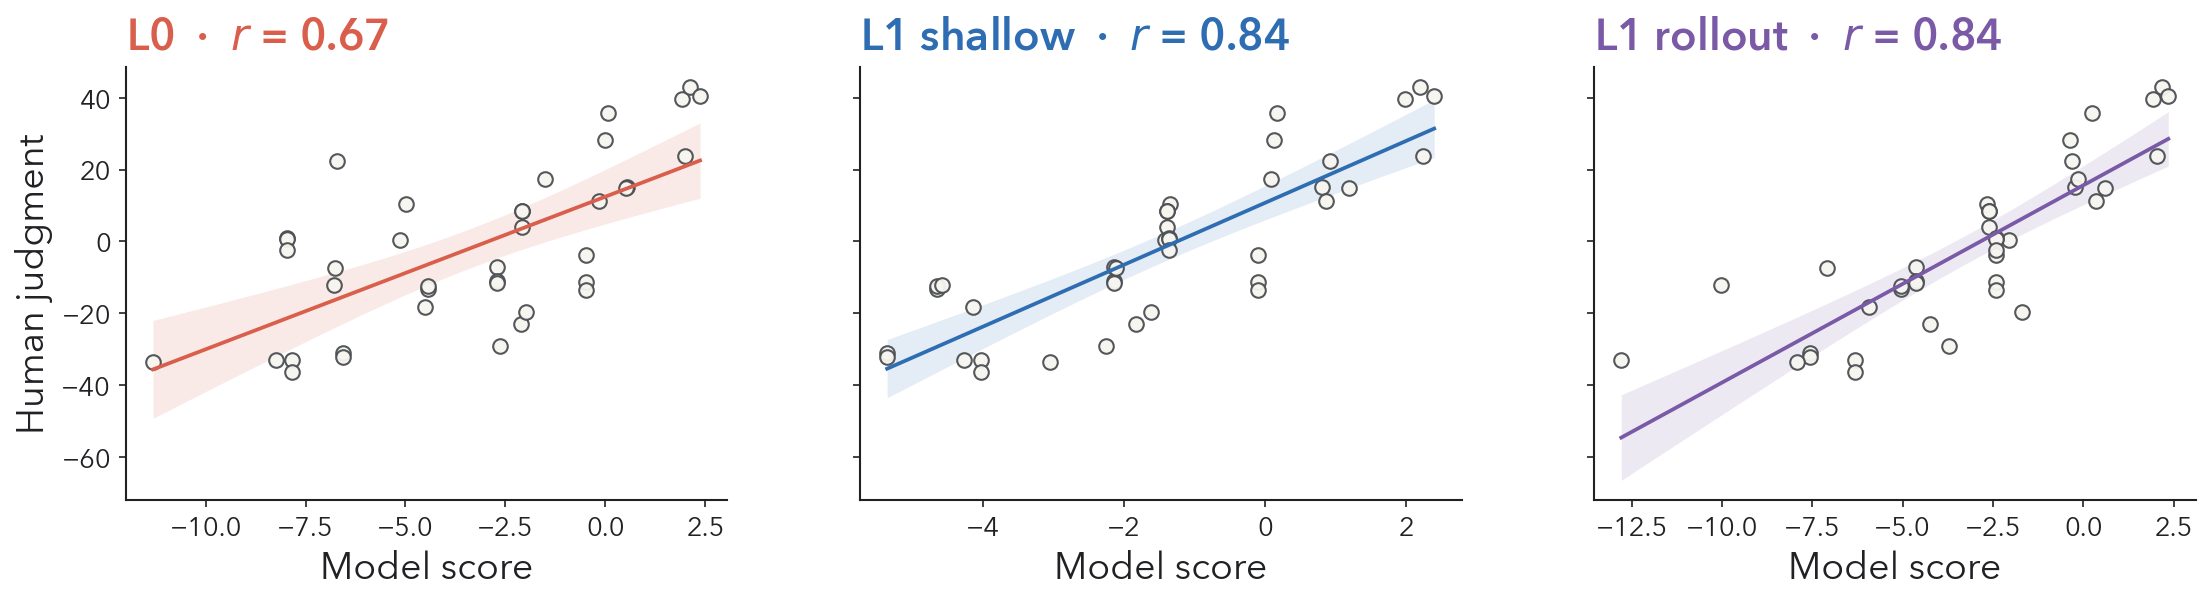

In [11]:
SCATTER_TAGS = ["L0", "L1 heuristic", "real L1"]

fig, axes = plot_model_human_scatters(
    dm["joe_univ"],
    datasets["joe_univ"],
    tags=SCATTER_TAGS,
    title=TITLES["scatter"],
    xlabel="Model score",
    ylabel="Human judgment",
    label_outliers=0,   # set to 2 or 3 to label the largest residuals
    figsize=POSTER_FIGSIZE["scatters"],
    stem="02_model_human_scatters",
)


### Optional diagnostic: compare L1 shallow and L1 rollout directly

Not used on the poster. Useful for diagnosing which scenarios distinguish the two models.


Saved: figures/poster_clean/optional_L1h_vs_realL1.pdf / .svg / .png at 5.30 × 5.00 in, 400 dpi


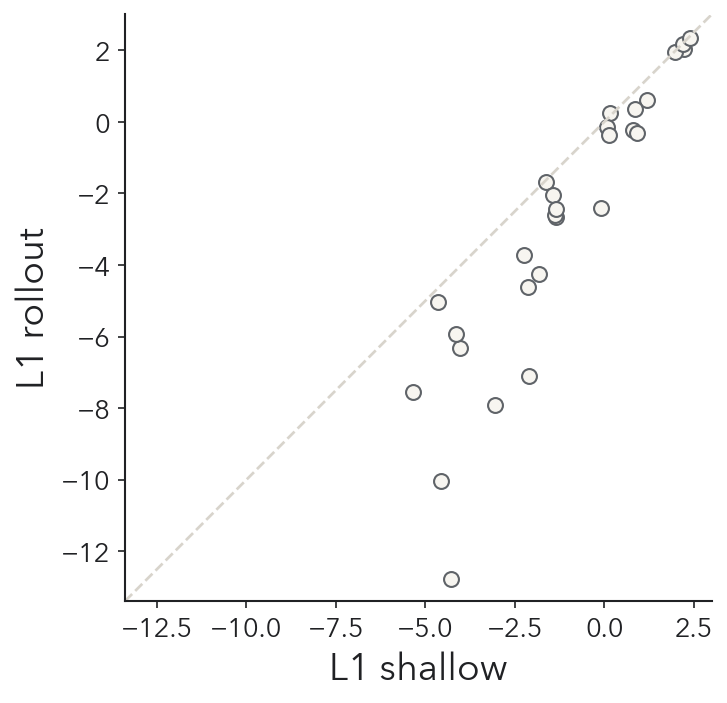

In [12]:
def plot_model_vs_model_clean(
    sims,
    tag_x="L1 heuristic",
    tag_y="real L1",
    metric="univ_aggregate_welfare",
    labels=MODEL_LABELS,
    color="#5F6368",
    label_largest=0,
    title=None,
    stem=None,
):
    xdf = sims[tag_x][["map", metric]].rename(columns={metric: "x"})
    ydf = sims[tag_y][["map", metric]].rename(columns={metric: "y"})
    df = xdf.merge(ydf, on="map").dropna()

    lo = min(df.x.min(), df.y.min())
    hi = max(df.x.max(), df.y.max())
    margin = 0.04 * (hi - lo)
    lo, hi = lo - margin, hi + margin

    fig, ax = plt.subplots(figsize=(5.3, 5.0))
    ax.plot([lo, hi], [lo, hi], color=STYLE["grid"], linewidth=1.3, linestyle="--")
    ax.scatter(
        df.x, df.y,
        s=STYLE["marker_size"] * 0.75,
        facecolor=STYLE["point_fill"],
        edgecolor=color, linewidth=1.0,
    )

    if label_largest:
        df["difference"] = np.abs(df.y - df.x)
        for _, row in df.nlargest(label_largest, "difference").iterrows():
            ax.annotate(
                row["map"], (row.x, row.y),
                xytext=(5, 5), textcoords="offset points",
                fontsize=STYLE["annotation_fontsize"] - 3,
                color=STYLE["secondary_text"],
            )

    ax.set_xlabel(labels.get(tag_x, tag_x))
    ax.set_ylabel(labels.get(tag_y, tag_y))
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")
    if title:
        ax.set_title(title, loc="left", fontweight="semibold")
    clean_axes(ax)
    fig.tight_layout()
    if stem:
        export_figure(fig, stem)
    return fig, ax, df

fig, ax, model_comparison_df = plot_model_vs_model_clean(
    sims,
    tag_x="L1 heuristic",
    tag_y="real L1",
    title=None,
    label_largest=0,
    stem="optional_L1h_vs_realL1",
)


## 6. Fit versus compute — Pearson $r$

Vertical whiskers show uncertainty in fit from the participant bootstrap. Horizontal whiskers show runtime interquartile ranges (IQRs), not inferential uncertainty. The x-axis is logarithmic.


Saved: figures/poster_clean/03_fit_vs_compute_r.pdf / .svg / .png at 6.85 × 5.13 in, 400 dpi


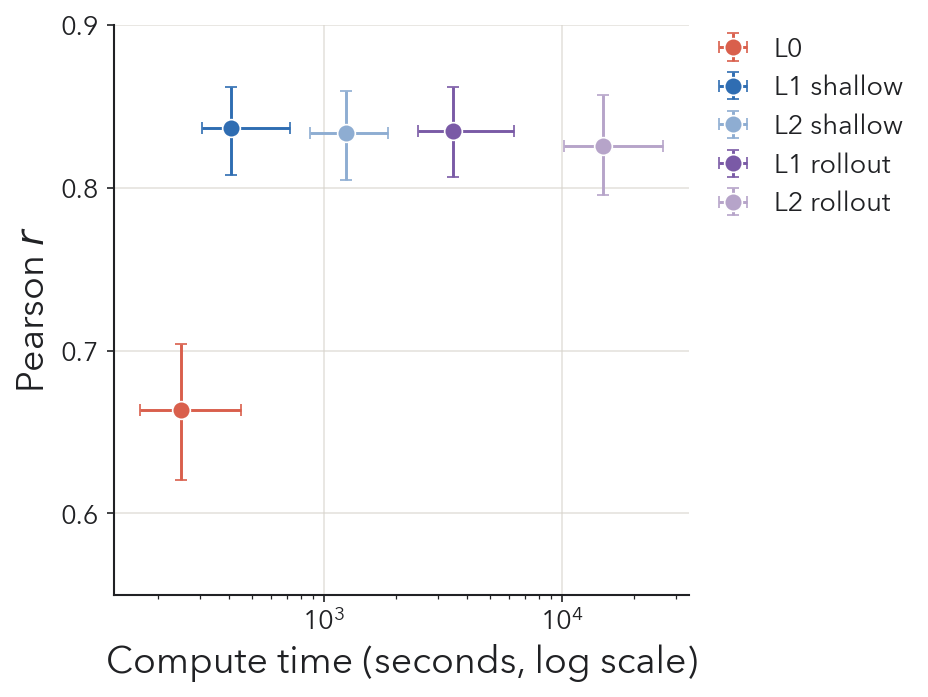

In [13]:
compute_samples = load_compute_samples(RUNS)

fig, ax = plot_fit_vs_compute(
    compute_samples,
    boot_r_univ,
    order=MODEL_ORDER,
    title=TITLES["fit_compute"],
    ylim=LIMITS["fit_compute_r"],
    show_compute_iqr=True,
    figsize=POSTER_FIGSIZE["fit_compute"],
    stem="03_fit_vs_compute_r",
)


## 7. Moral judgment — $\Delta R^2$ beyond outcomes

Here the incremental metric is the scientifically natural one. Welfare, harm, and inequality are genuine alternative predictors of moral judgment, so $\Delta R^2$ asks whether each model's universalization score contributes beyond them.

The first figure gives the compact US + pooled-20-country result. The second is an optional country-level forest plot in the same metric.


Saved: figures/poster_clean/04_moral_judgment_delta_r2.pdf / .svg / .png at 15.00 × 6.27 in, 400 dpi


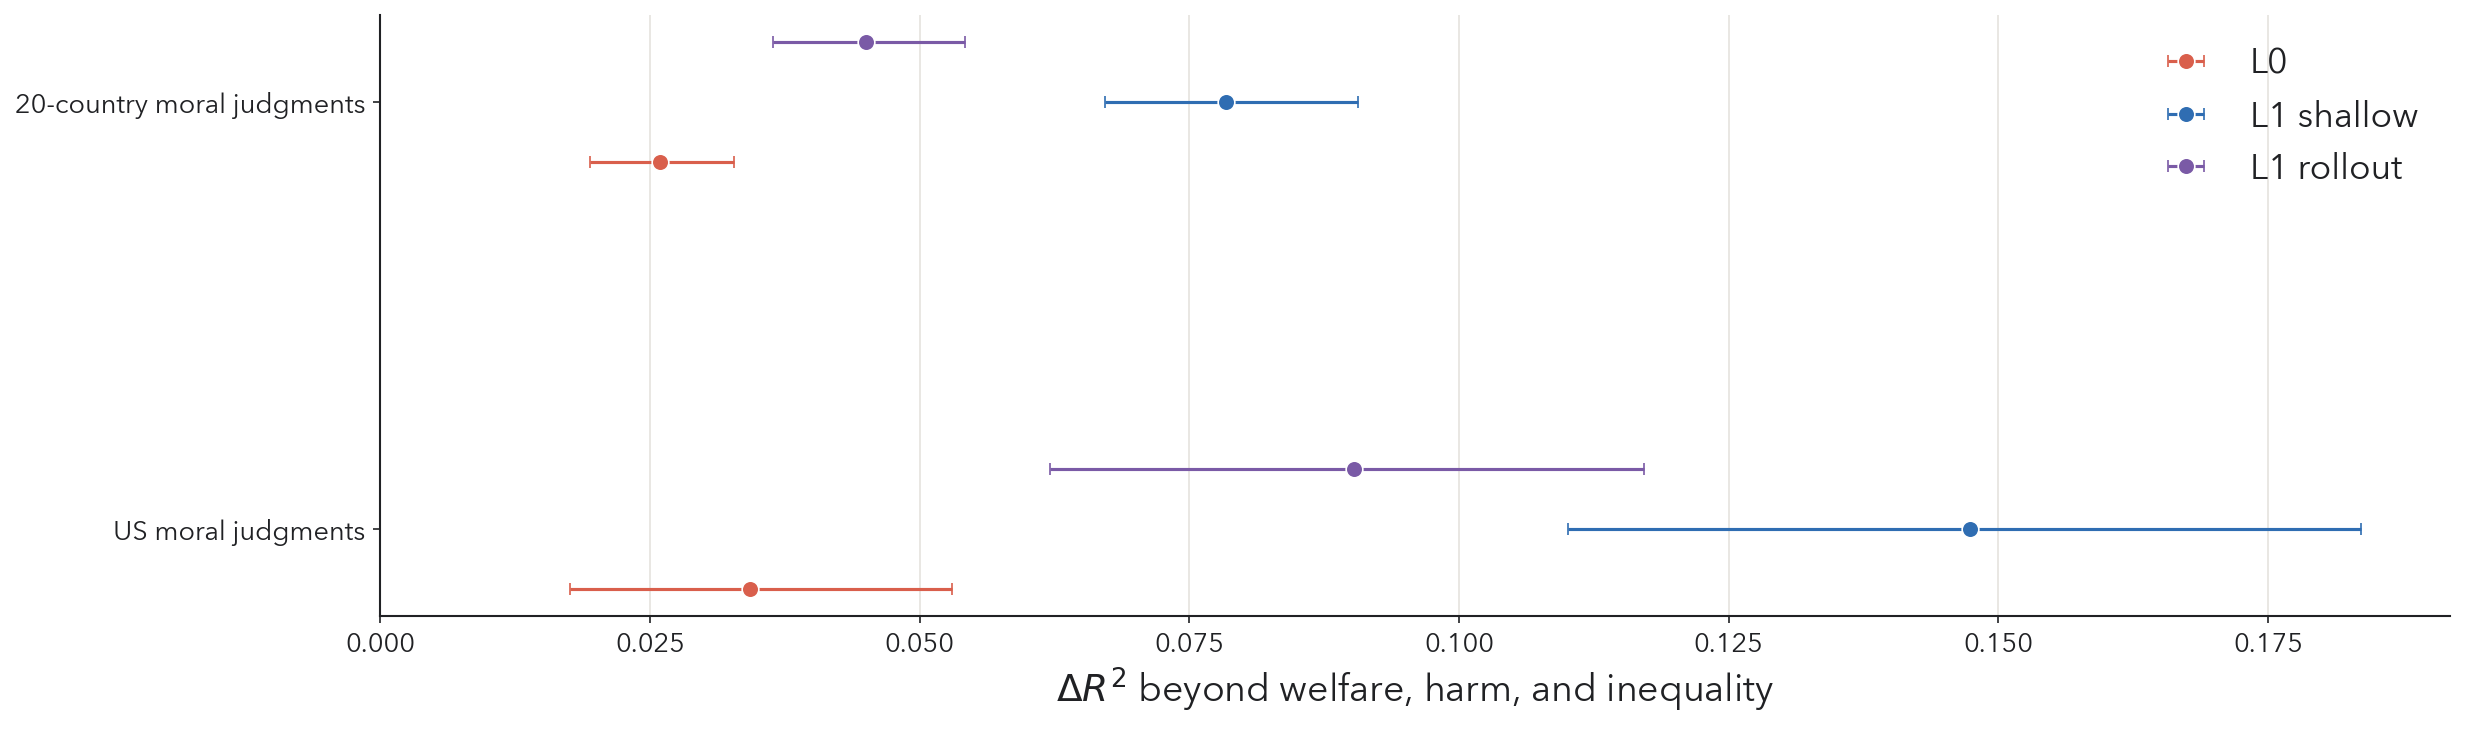

In [14]:
moral_boot = {}

_, moral_boot["joe_moral"] = bootstrap_delta_r2(
    dm["joe_moral"], datasets["joe_moral"],
    n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
)
_, moral_boot["logan_moral"] = bootstrap_delta_r2(
    dm["logan_moral"], datasets["logan_moral"],
    n_boot=N_BOOT_POSTER, seed=BOOT_SEED,
)

MORAL_DATASET_LABELS = {
    "joe_moral": "US moral judgments",
    "logan_moral": "20-country moral judgments",
}

fig, ax = plot_moral_dr2(
    moral_boot,
    MORAL_DATASET_LABELS,
    model_tags=("L0", "L1 heuristic", "real L1"),
    title=TITLES["moral_dr2"],
    xlim=LIMITS["moral_dr2"],
    figsize=POSTER_FIGSIZE["us_dr2"],
    stem="04_moral_judgment_delta_r2",
)


In [15]:
# Pooled moral-judgment tests.
# First: does each model add predictive value beyond outcome-based controls?
# Second: paired differences of ΔR² across models, mirroring the r contrasts above.

def bootstrap_effect_vs_zero(values, label, ci=95):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    alpha = (100 - ci) / 2
    lo, hi = np.percentile(values, [alpha, 100 - alpha])
    # Add-one smoothing: bootstrap p can never be exactly 0 (floor = 2/(n+1)).
    n = values.size
    n_le = int((values <= 0).sum())
    n_ge = int((values >= 0).sum())
    p_two_sided = min(1.0, 2 * (min(n_le, n_ge) + 1) / (n + 1))
    p_gt_0 = np.mean(values > 0)
    return {
        "model": label,
        "mean_delta_r2": np.mean(values),
        "ci_lo": lo,
        "ci_hi": hi,
        "p_two_sided_vs_0": p_two_sided,
        "prob_gt_0": p_gt_0,
        "n_boot": values.size,
    }


moral_test_tables = {}

for dataset_key, dataset_label in MORAL_DATASET_LABELS.items():
    boot = moral_boot[dataset_key]

    effect_rows = [
        bootstrap_effect_vs_zero(boot[tag], MODEL_LABELS.get(tag, tag))
        for tag in ["L0", "L1 heuristic", "real L1"]
    ]
    effects = pd.DataFrame(effect_rows)
    effects.insert(0, "dataset", dataset_label)

    contrasts = contrast_table(
        boot,
        PRIMARY_CONTRASTS,
        metric_label="Difference in ΔR²",
    )
    contrasts.insert(0, "dataset", dataset_label)

    moral_test_tables[dataset_key] = {
        "effects_vs_zero": effects,
        "paired_model_contrasts": contrasts,
    }

    print(f"\n{dataset_label}: each model's ΔR² versus zero")
    display(effects.round({
        "mean_delta_r2": 4, "ci_lo": 4, "ci_hi": 4,
        "p_two_sided_vs_0": 4, "prob_gt_0": 4,
    }))

    print(f"{dataset_label}: paired differences in ΔR²")
    display(contrasts.round({
        "mean_diff": 4, "ci_lo": 4, "ci_hi": 4,
        "p_two_sided": 4, "prob_a_gt_b": 4,
    }))

    effects.to_csv(FIG_DIR / f"{dataset_key}_delta_r2_vs_zero.csv", index=False)
    contrasts.to_csv(FIG_DIR / f"{dataset_key}_paired_delta_r2_contrasts.csv", index=False)



US moral judgments: each model's ΔR² versus zero


,dataset,model,mean_delta_r2,ci_lo,ci_hi,p_two_sided_vs_0,prob_gt_0,n_boot
0,US moral judgments,L0,0.0343,0.0176,0.0530,0.001,1.0,2000
1,US moral judgments,L1 shallow,0.1473,0.1101,0.1836,0.001,1.0,2000
2,US moral judgments,L1 rollout,0.0903,0.0621,0.1172,0.001,1.0,2000


US moral judgments: paired differences in ΔR²


,dataset,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,US moral judgments,Difference in ΔR²,Shallow prediction improves on no prediction,L1 shallow − L0,0.1131,0.0873,0.1396,0.001,1.0,2000
1,US moral judgments,Difference in ΔR²,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.0571,-0.0743,-0.0421,0.001,0.0,2000



20-country moral judgments: each model's ΔR² versus zero


,dataset,model,mean_delta_r2,ci_lo,ci_hi,p_two_sided_vs_0,prob_gt_0,n_boot
0,20-country moral judgments,L0,0.0259,0.0195,0.0328,0.001,1.0,2000
1,20-country moral judgments,L1 shallow,0.0784,0.0672,0.0906,0.001,1.0,2000
2,20-country moral judgments,L1 rollout,0.0450,0.0364,0.0542,0.001,1.0,2000


20-country moral judgments: paired differences in ΔR²


,dataset,metric,claim,comparison,mean_diff,ci_lo,ci_hi,p_two_sided,prob_a_gt_b,n_boot
0,20-country moral judgments,Difference in ΔR²,Shallow prediction improves on no prediction,L1 shallow − L0,0.0525,0.0440,0.0615,0.001,1.0,2000
1,20-country moral judgments,Difference in ΔR²,Rollout improves on shallow prediction,L1 rollout − L1 shallow,-0.0334,-0.0387,-0.0284,0.001,0.0,2000


### US-sample ΔR² figure — same format as the fit figure

Replaces the two-dataset fig 04 on the poster (its pooled row duplicates the country forest's first row). Two variants are exported: **5 models** (recommended — matches the model grid; readers will ask about the missing two otherwise) and **3 models** (fallback if the column is crowded).

Suggested caption: **ΔR² from adding each model's universalization score beyond outcome-based measures; whiskers show 95% participant-bootstrap CIs.**


US ΔR² — model tags available in bootstrap: ['L0', 'L1 heuristic', 'L2 heuristic', 'real L1', 'real L2']
Saved: figures/poster_clean/04b_us_moral_dr2_5models.pdf / .svg / .png at 15.00 × 6.27 in, 400 dpi
Saved: figures/poster_clean/04c_us_moral_dr2_3models.pdf / .svg / .png at 15.00 × 6.27 in, 400 dpi


,tag,mean,median,lo,hi
0,L0,0.034,0.034,0.018,0.053
1,L1 heuristic,0.147,0.147,0.110,0.184
2,L2 heuristic,0.145,0.146,0.107,0.181
3,real L1,0.090,0.091,0.062,0.117
4,real L2,0.102,0.102,0.071,0.132


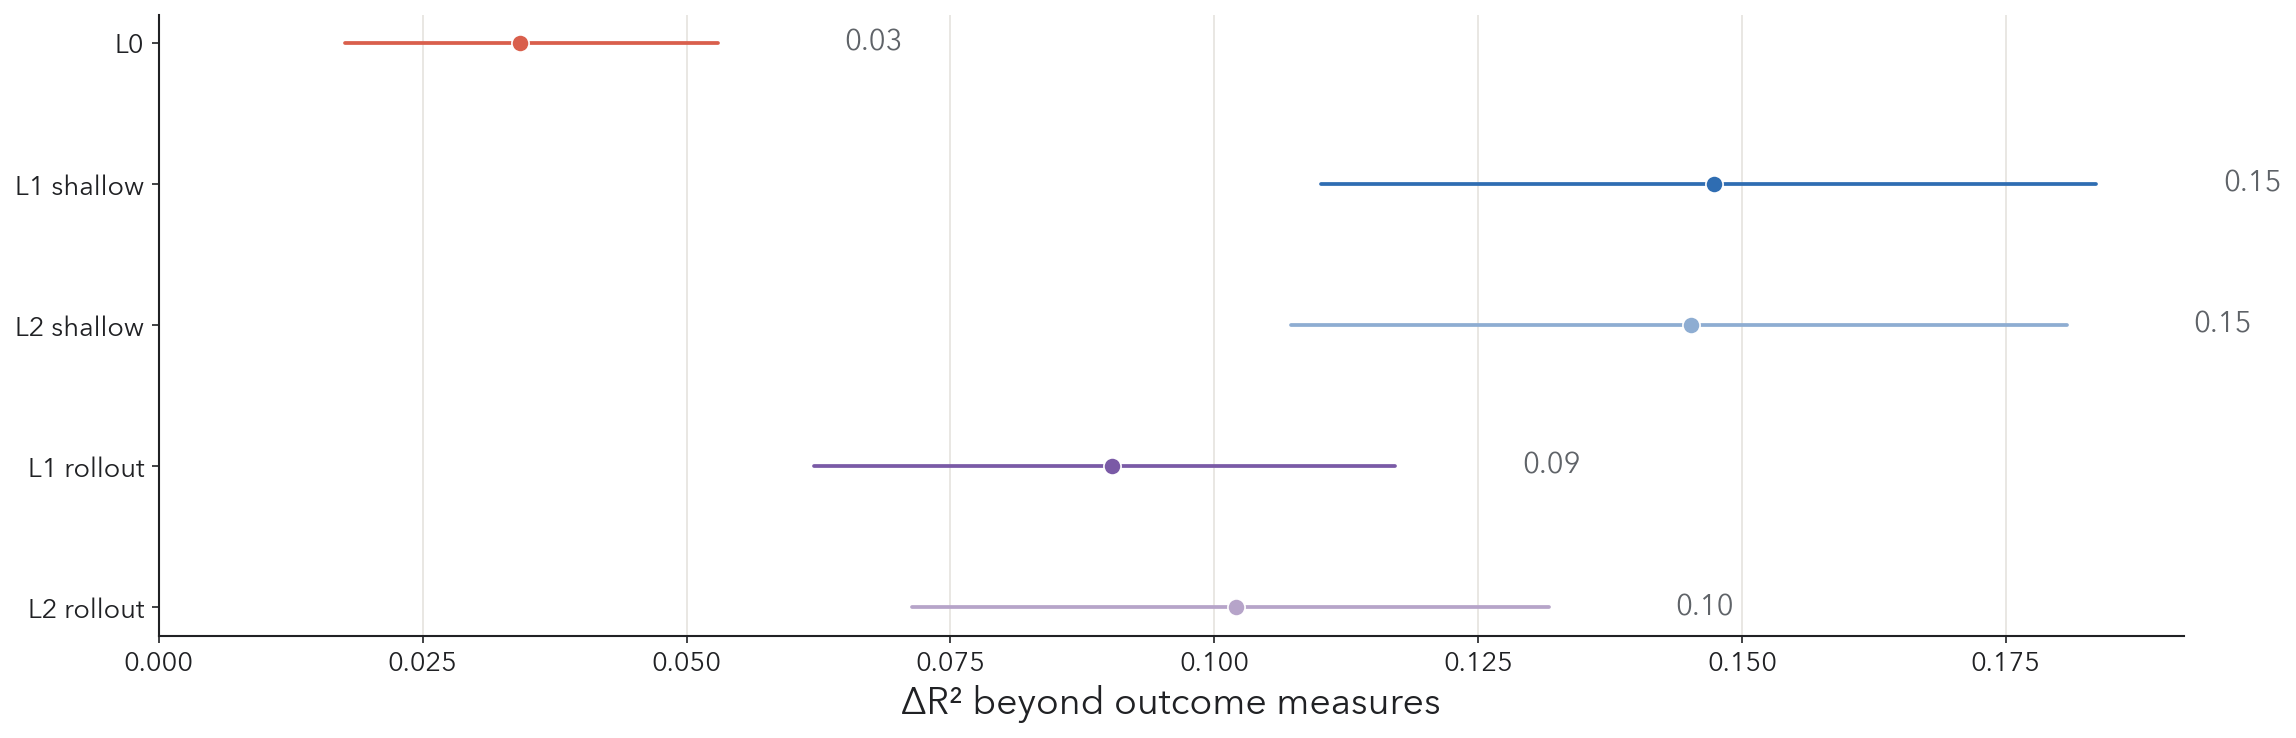

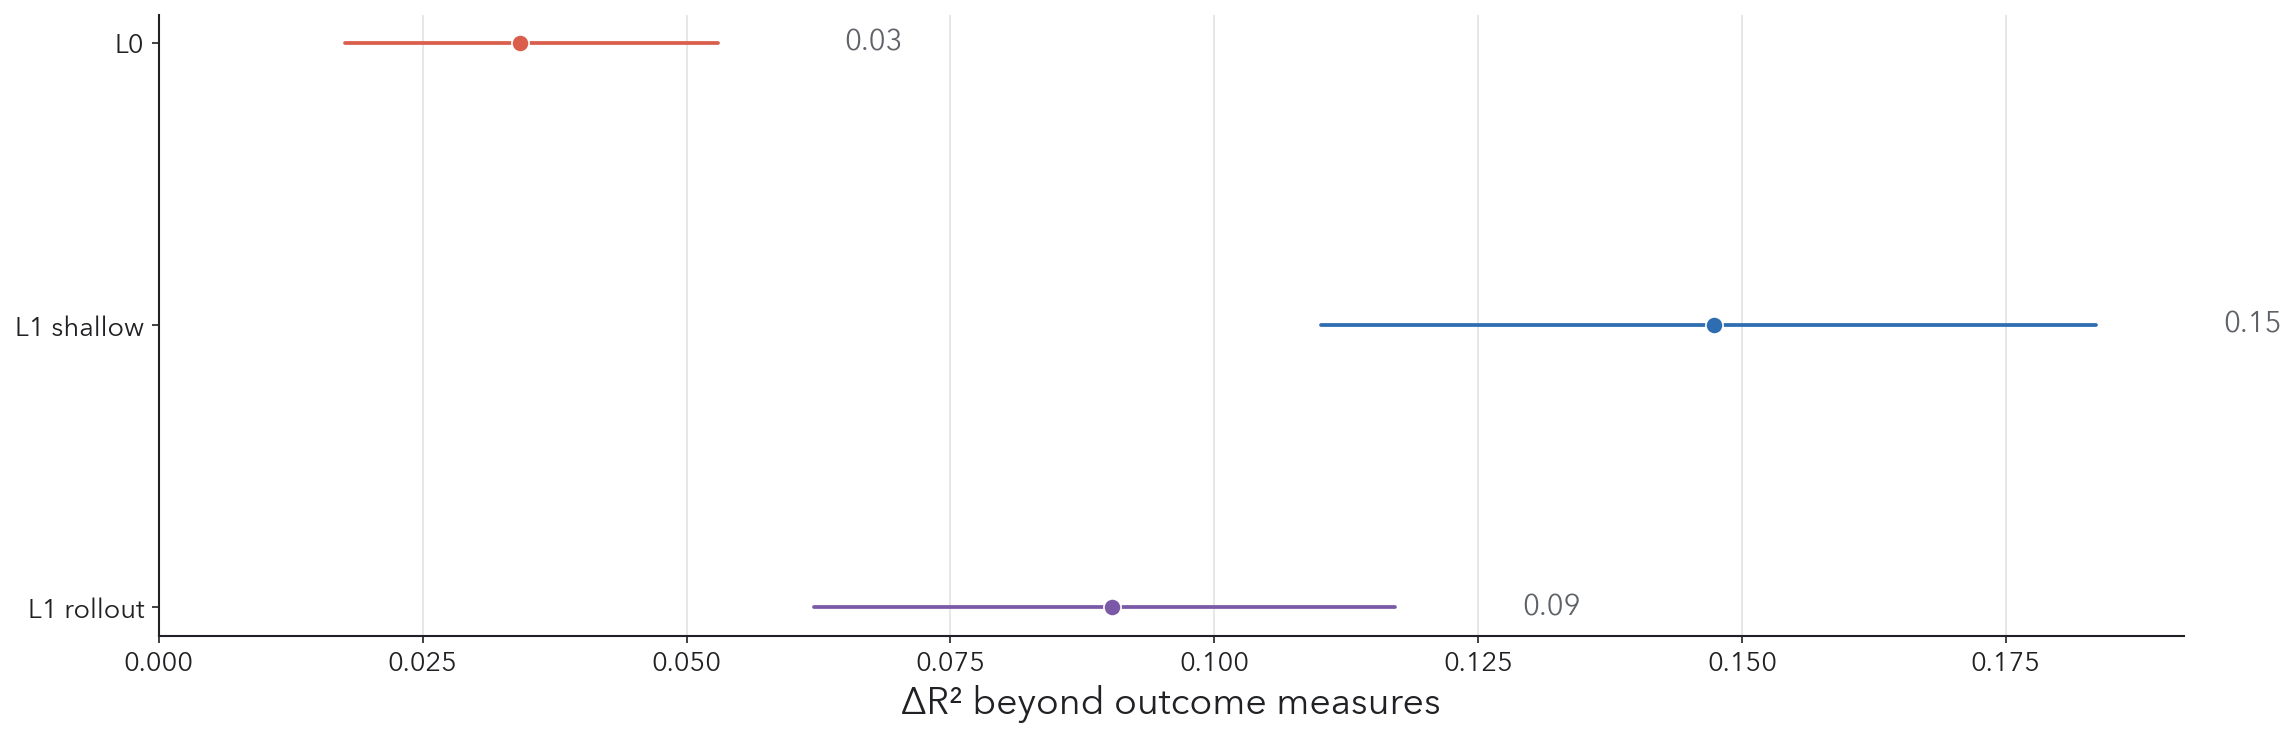

In [16]:
# US-sample ΔR² per model, in the same visual format as the fit figure.
US_DR2_XLABEL = "ΔR² beyond outcome measures"

_avail = [t for t in MODEL_ORDER if t in moral_boot["joe_moral"]]
print("US ΔR² — model tags available in bootstrap:", _avail)
if len(_avail) < 5:
    print("NOTE: fewer than 5 tags available; the 5-model figure will show only these. "
          "If you want all 5, ensure bootstrap_delta_r2 covers every tag in RUNS.")

fig, ax, us_dr2_5 = plot_bootstrap_intervals(
    moral_boot["joe_moral"],
    order=MODEL_ORDER,
    xlabel=US_DR2_XLABEL,
    xlim=LIMITS["moral_dr2"],
    value_decimals=2,
    figsize=POSTER_FIGSIZE["us_dr2"],
    stem="04b_us_moral_dr2_5models",
)

fig, ax, us_dr2_3 = plot_bootstrap_intervals(
    moral_boot["joe_moral"],
    order=["L0", "L1 heuristic", "real L1"],
    xlabel=US_DR2_XLABEL,
    xlim=LIMITS["moral_dr2"],
    value_decimals=2,
    figsize=POSTER_FIGSIZE["us_dr2"],
    stem="04c_us_moral_dr2_3models",
)

us_dr2_5.round(3)


### What to report on the poster

The most economical reporting is:

- **Universalizability fit:** L1 shallow minus L0, followed by its 95% paired-bootstrap CI.
- **Rollout comparison:** real L1 minus L1 shallow, preferably as an effect estimate and CI rather than merely “not significant.”
- **Moral judgments:** pooled L1-shallow $\Delta R^2$ versus zero, plus the two paired $\Delta R^2$ contrasts if space permits.

Do not infer model differences from overlapping individual confidence intervals; use the paired contrast table generated above.


### Optional country-level $\Delta R^2$ forest plot

This can take a few minutes without `fast_bootstrap`. For the poster, the pooled result may be clearer; keep the country plot only if its pattern is visually stable and legible at print size.


## Cross-cultural model comparison

The poster uses country-level $\Delta R^2$ for the cross-cultural figure: how much does each model-derived universalization score add beyond welfare, harm, and inequality? The pooled row is the inferential headline; country rows are descriptive and noisier.

Raw-$r$ country plots are available as a diagnostic if `RUN_COUNTRY_R_BOOTSTRAPS=True`, but the controlled $\Delta R^2$ figure is the poster-facing version.


In [17]:
FOCAL_MODELS = ["L0", "L1 heuristic", "real L1"]


def _pooled_r_rows(boot_r, label="Pooled (20 countries)"):
    rows = []
    for tag in FOCAL_MODELS:
        values = np.asarray(boot_r[tag], dtype=float)
        values = values[np.isfinite(values)]
        rows.append({
            "country": label,
            "tag": tag,
            "mean": np.mean(values),
            "lo": np.percentile(values, 2.5),
            "hi": np.percentile(values, 97.5),
            "pooled": True,
        })
    return rows


def plot_country_model_fits(
    country_df,
    tags=FOCAL_MODELS,
    labels=MODEL_LABELS,
    colors=MODEL_COLORS,
    pooled_label="Pooled (20 countries)",
    sort_by="L1 heuristic",
    xlabel="Pearson $r$",
    title=None,
    xlim=None,
    figsize=(7.6, 9.6),
    stem=None,
):
    """Three-model country forest plot with a pooled row and paired visual offsets."""
    df = country_df.copy()
    pooled = df[df["country"] == pooled_label]
    countries = df[df["country"] != pooled_label]

    order = (
        countries[countries["tag"] == sort_by]
        .sort_values("mean", ascending=False)["country"]
        .tolist()
    )
    display_order = [pooled_label] + order
    base_y = np.arange(len(display_order))[::-1]
    offsets = np.linspace(0.22, -0.22, len(tags))

    fig, ax = plt.subplots(figsize=figsize)
    for offset, tag in zip(offsets, tags):
        sub = df[df["tag"] == tag].set_index("country").loc[display_order]
        y = base_y + offset
        ax.errorbar(
            sub["mean"], y,
            xerr=[sub["mean"] - sub["lo"], sub["hi"] - sub["mean"]],
            fmt="o", markersize=6.2,
            color=colors[tag], ecolor=colors[tag],
            elinewidth=1.2, capsize=2,
            markeredgecolor="white", markeredgewidth=0.7,
            label=labels.get(tag, tag),
        )

    ax.set_yticks(base_y)
    ax.set_yticklabels(display_order)
    ax.get_yticklabels()[0].set_fontweight("semibold")
    ax.axhline(base_y[0] - 0.55, color=STYLE["secondary_text"], linewidth=1.0, linestyle=":")
    ax.axvline(0, color=STYLE["secondary_text"], linewidth=0.9)
    ax.set_xlabel(xlabel)
    if title:
        ax.set_title(title, loc="left", fontweight="semibold", pad=10)
    if xlim:
        ax.set_xlim(*xlim)
    else:
        # Preserve the full uncertainty intervals, including values below zero.
        xmin = float(df["lo"].min())
        xmax = float(df["hi"].max())
        xmin = min(xmin, 0.0)
        xmax = max(xmax, 0.0)
        span = max(xmax - xmin, 1e-6)
        pad = 0.05 * span
        ax.set_xlim(xmin - pad, xmax + pad)

    ax.legend(frameon=False, loc="lower right", fontsize=STYLE["tick_fontsize"])
    clean_axes(ax, grid_axis="x")
    fig.tight_layout(pad=1.1)
    if stem:
        export_figure(fig, stem)
    return fig, ax


In [18]:
# Main cross-cultural figure: raw model–judgment correlations by country.
if RUN_COUNTRY_R_BOOTSTRAPS:
    country_r_rows = []

    # Pooled row uses the same individual-participant bootstrap as the pooled analysis.
    _, pooled_r_boot = bootstrap_over_participants(
        {tag: dm["logan_moral"][tag] for tag in FOCAL_MODELS},
        datasets["logan_moral"],
        n_boot=N_BOOT_COUNTRY,
        seed=BOOT_SEED,
    )
    country_r_rows.extend(_pooled_r_rows(pooled_r_boot))

    for country, experiment in sorted(logan_by_country.items()):
        country_dm = build_all_design_matrices(
            {tag: sims[tag] for tag in FOCAL_MODELS},
            out_df,
            experiment,
        )
        _, boot = bootstrap_over_participants(
            country_dm,
            experiment,
            n_boot=N_BOOT_COUNTRY,
            seed=BOOT_SEED,
        )
        for tag in FOCAL_MODELS:
            values = np.asarray(boot[tag], dtype=float)
            values = values[np.isfinite(values)]
            country_r_rows.append({
                "country": country,
                "tag": tag,
                "mean": np.mean(values),
                "lo": np.percentile(values, 2.5),
                "hi": np.percentile(values, 97.5),
                "pooled": False,
            })

    country_r = pd.DataFrame(country_r_rows)
    country_r.to_csv(FIG_DIR / "country_model_fits_r.csv", index=False)

    fig, ax = plot_country_model_fits(
        country_r,
        title=TITLES.get("country_r"),
        xlabel="Pearson $r$",
        stem="05_country_model_fits_r",
    )
else:
    print("Country r bootstraps skipped. Set RUN_COUNTRY_R_BOOTSTRAPS=True to run them.")


Country r bootstraps skipped. Set RUN_COUNTRY_R_BOOTSTRAPS=True to run them.


In [19]:
# Per-country paired contrasts in raw r. These support the verbal claim about model ranking.
if RUN_COUNTRY_R_BOOTSTRAPS:
    country_contrast_rows = []
    for country, experiment in sorted(logan_by_country.items()):
        country_dm = build_all_design_matrices(
            {tag: sims[tag] for tag in FOCAL_MODELS}, out_df, experiment
        )
        _, boot = bootstrap_over_participants(
            country_dm, experiment,
            n_boot=N_BOOT_COUNTRY, seed=BOOT_SEED,
        )
        for a, b, claim in PRIMARY_CONTRASTS:
            row = paired_bootstrap_contrast(boot, a, b)
            row.update({"country": country, "claim": claim})
            country_contrast_rows.append(row)

    country_r_contrasts = pd.DataFrame(country_contrast_rows)
    country_r_contrasts.to_csv(FIG_DIR / "country_paired_r_contrasts.csv", index=False)

    summary_counts = (
        country_r_contrasts.assign(positive=lambda d: d["mean_diff"] > 0)
        .groupby("claim")["positive"]
        .agg(["sum", "count"])
        .reset_index()
    )
    display(summary_counts)


fsSelection bit 5 (bold) and head table macStyle bit 0 (bold) should match


Saved: figures/poster_clean/optional_country_model_delta_r2.pdf / .svg / .png at 8.51 × 10.75 in, 400 dpi


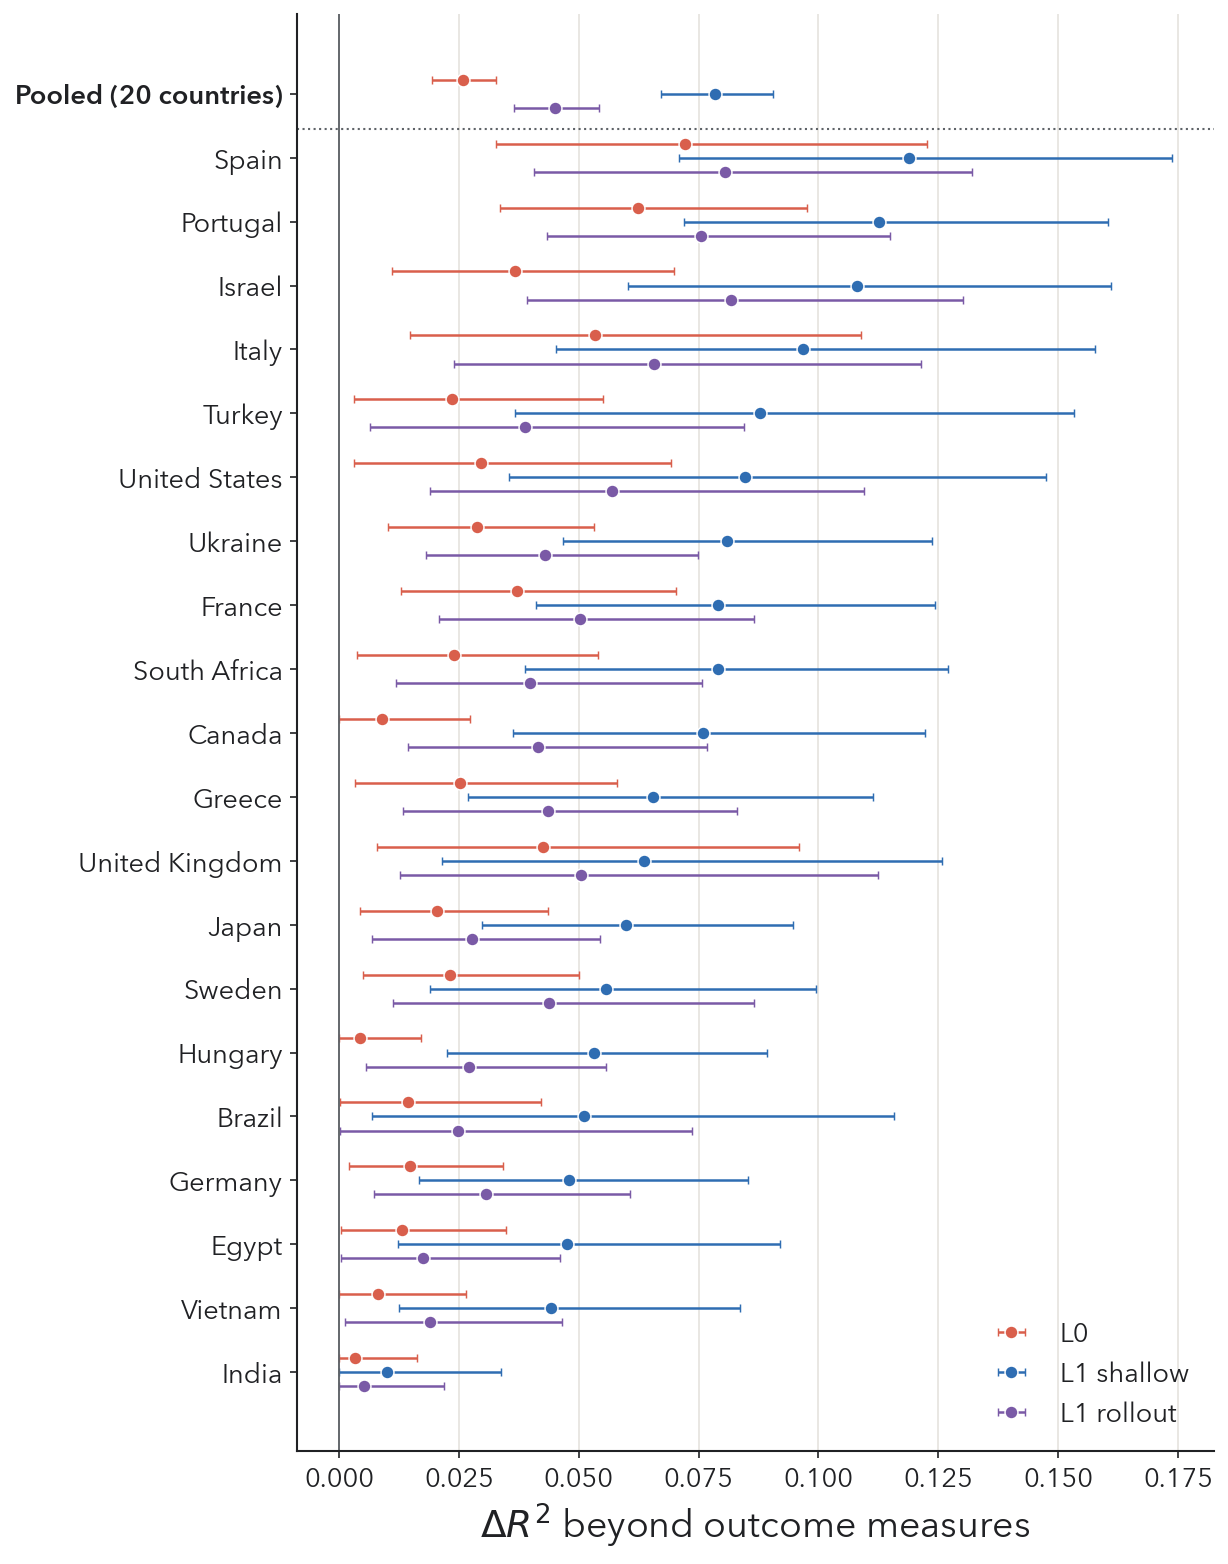

In [20]:
# Optional robustness figure: per-country incremental ΔR² for all three models.
# This is more directly tied to unique contribution beyond outcome controls, but may be noisy.
if RUN_COUNTRY_DR2_BOOTSTRAPS:
    country_dr2_rows = []

    for tag in FOCAL_MODELS:
        values = np.asarray(moral_boot["logan_moral"][tag], dtype=float)
        values = values[np.isfinite(values)]
        country_dr2_rows.append({
            "country": "Pooled (20 countries)",
            "tag": tag,
            "mean": np.mean(values),
            "lo": np.percentile(values, 2.5),
            "hi": np.percentile(values, 97.5),
            "pooled": True,
        })

    for country, experiment in sorted(logan_by_country.items()):
        country_dm = build_all_design_matrices(
            {tag: sims[tag] for tag in FOCAL_MODELS}, out_df, experiment
        )
        _, boot = bootstrap_delta_r2(
            country_dm, experiment,
            n_boot=N_BOOT_COUNTRY, seed=BOOT_SEED,
        )
        for tag in FOCAL_MODELS:
            values = np.asarray(boot[tag], dtype=float)
            values = values[np.isfinite(values)]
            country_dr2_rows.append({
                "country": country,
                "tag": tag,
                "mean": np.mean(values),
                "lo": np.percentile(values, 2.5),
                "hi": np.percentile(values, 97.5),
                "pooled": False,
            })

    country_dr2_all = pd.DataFrame(country_dr2_rows)
    country_dr2_all.to_csv(FIG_DIR / "country_model_delta_r2.csv", index=False)

    fig, ax = plot_country_model_fits(
        country_dr2_all,
        xlabel="$\\Delta R^2$ beyond outcome measures",
        xlim=None,
        figsize=POSTER_FIGSIZE["country_dr2"],
        stem="optional_country_model_delta_r2",
    )
else:
    print("Per-country ΔR² bootstraps skipped; pooled ΔR² is still computed above.")


### Final caption for the country-level $\Delta R^2$ figure

**Pooled data favor shallow prediction. Country-level estimates show the same broad pattern but are individually uncertain.**

Points show incremental $R^2$ from adding each model-derived universalization score beyond aggregate welfare, harm, and inequality. Whiskers show 95% participant-bootstrap CIs. The pooled estimate is shown first; countries are ordered by the L1-shallow estimate rather than by a model-difference contrast.

The x-axis extends below zero whenever needed, so confidence intervals are not clipped.


### PowerPoint captions for the moral section

**Pooled controlled analysis**  
*Incremental $R^2$ from adding each model-derived universalization score beyond aggregate welfare, harm, and inequality; whiskers show 95% participant-bootstrap confidence intervals.*

**Country comparison**  
*Points show correlations between model scores and country-mean moral judgments; whiskers show 95% participant-bootstrap confidence intervals. The pooled estimate is shown first.*

A concise synthesis line, conditional on the generated contrasts, is:  
**Across countries, shallow prediction improves on the no-prediction baseline, while deeper rollout adds little.**


## 8. Poster export checklist

- Use the exported **400-dpi PNGs** in PowerPoint via Insert/Change Picture.
- Keep each figure's aspect ratio fixed; the notebook `figsize` values match the PowerPoint boxes.
- Confirm PowerPoint uses **Avenir Next** rather than substituting a font.
- Do not describe small nominal differences within the shallow family as meaningful unless paired bootstrap contrasts support them.
- For moral judgments, explain that $\Delta R^2$ is used because outcome-based measures also matter.
